In [ ]:
#1 Mount Drive and imports
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
import shap

DRIVE_PATH = "/content/drive/MyDrive/Capstone/Data_2/"

DRIVE_PATH1 =  "/content/drive/MyDrive/Capstone/"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
#2 Loading NHANES data and the three fitted NHANES models
X_train = pd.read_csv(DRIVE_PATH + "NHANES_X_train_clean.csv")
X_test = pd.read_csv(DRIVE_PATH + "NHANES_X_test_clean.csv")
y_train = pd.read_csv(DRIVE_PATH + "NHANES_y_train_clean.csv").squeeze()
y_test = pd.read_csv(DRIVE_PATH + "NHANES_y_test_clean.csv").squeeze()

best_lr_nhanes = joblib.load(DRIVE_PATH1 + "models/nhanes_logistic_regression_pipeline.pkl")
best_rf_nhanes = joblib.load(DRIVE_PATH1 + "models/nhanes_random_forest_pipeline.pkl")
best_xgb_nhanes = joblib.load(DRIVE_PATH1 + "models/nhanes_xgboost_pipeline.pkl")

print("Everything loaded successfully")

Everything loaded successfully


In [ ]:
#3 Verification — confirm these are the final, correct models
print("LR:", best_lr_nhanes.named_steps["clf"].get_params()["C"], best_lr_nhanes.named_steps["clf"].get_params()["penalty"])
print("RF:", best_rf_nhanes.named_steps["clf"].get_params()["max_depth"], best_rf_nhanes.named_steps["clf"].get_params()["n_estimators"])
print("XGB:", best_xgb_nhanes.named_steps["clf"].get_params()["max_depth"], best_xgb_nhanes.named_steps["clf"].get_params()["learning_rate"])

LR: 1 l2
RF: 5 400
XGB: 3 0.01


In [ ]:
#4 Building the explainers
rf_classifier = best_rf_nhanes.named_steps["clf"]
xgb_classifier = best_xgb_nhanes.named_steps["clf"]

rf_explainer = shap.TreeExplainer(rf_classifier)
xgb_explainer = shap.TreeExplainer(xgb_classifier)

rf_shap_values = rf_explainer(X_test)
xgb_shap_values = xgb_explainer(X_test)

print("Tree explainers ready")

Tree explainers ready


In [ ]:
#5 Linear explainer for Logistic Regression — corrected
lr_classifier = best_lr_nhanes.named_steps["clf"]

X_test_scaled_for_shap = pd.DataFrame(
    best_lr_nhanes.named_steps["scaler"].transform(X_test),
    columns=X_test.columns
)

# Pass the masker as the single second argument — don't also pass
# X_test_scaled_for_shap positionally alongside it
lr_explainer = shap.LinearExplainer(
    lr_classifier,
    shap.maskers.Independent(X_test_scaled_for_shap, max_samples=X_test_scaled_for_shap.shape[0])
)
lr_shap_values = lr_explainer(X_test_scaled_for_shap)

print("Linear explainer ready — using full test set as background")

Linear explainer ready — using full test set as background


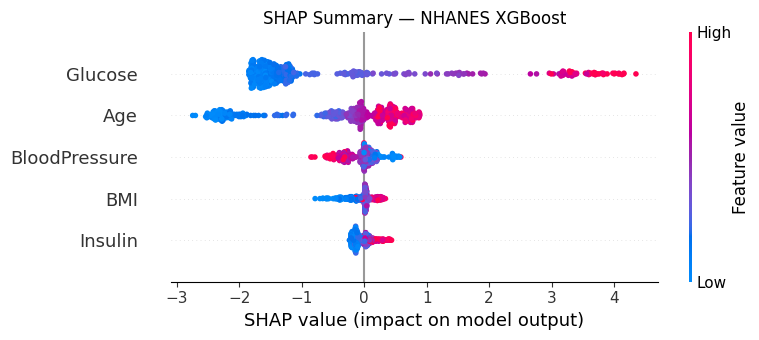

In [ ]:
#6 SHAP Summary — XGBoost
shap.plots.beeswarm(xgb_shap_values, show=False)
plt.title("SHAP Summary — NHANES XGBoost")
plt.tight_layout()
plt.show()

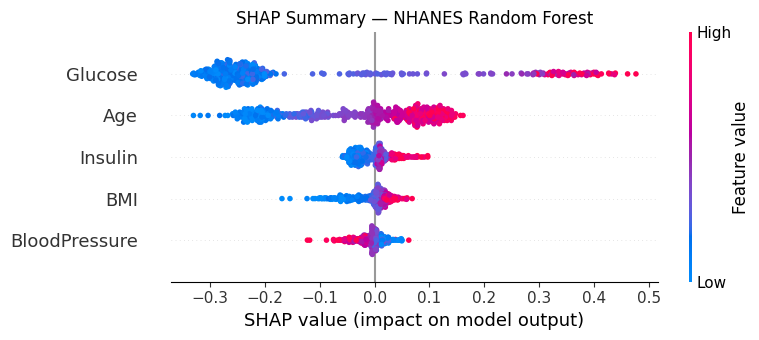

In [ ]:
#7 SHAP Summary — Random Forest
shap.plots.beeswarm(rf_shap_values[:, :, 1], show=False)
plt.title("SHAP Summary — NHANES Random Forest")
plt.tight_layout()
plt.show()

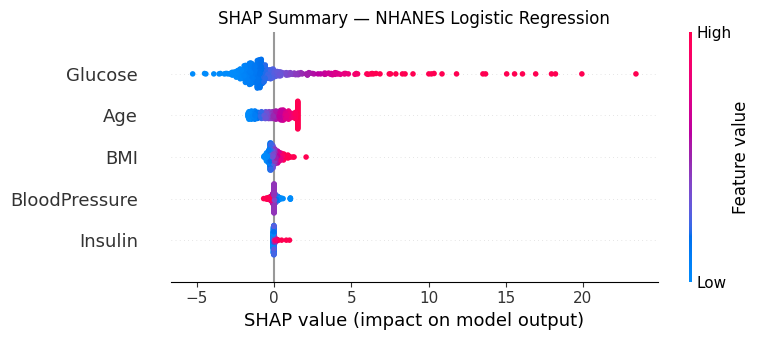

In [ ]:
#8 SHAP Summary — Logistic Regression
shap.plots.beeswarm(lr_shap_values, show=False)
plt.title("SHAP Summary — NHANES Logistic Regression")
plt.tight_layout()
plt.show()

In [ ]:
#9 The key test: does the Insulin-Glucose interaction still show up on NHANES?
shap.plots.scatter(xgb_shap_values[:, "Insulin"], color=xgb_shap_values[:, "Glucose"], show=False)
plt.title("SHAP Dependence — Insulin (colored by Glucose) — NHANES XGBoost")
plt.tight_layout()
plt.show()

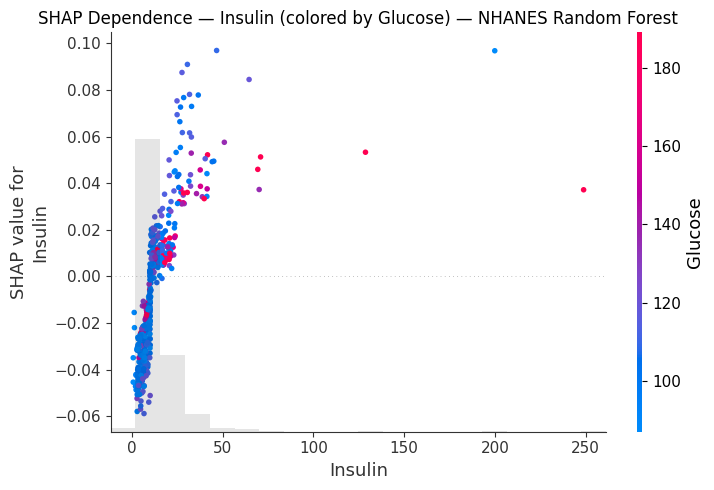

In [ ]:
#10 Same dependence plot for Random Forest, for comparison
shap.plots.scatter(rf_shap_values[:, "Insulin", 1], color=rf_shap_values[:, "Glucose", 1], show=False)
plt.title("SHAP Dependence — Insulin (colored by Glucose) — NHANES Random Forest")
plt.tight_layout()
plt.show()

In [ ]:
#11 Getting predictions for local explanations
y_pred_xgb = best_xgb_nhanes.predict(X_test)
y_prob_xgb = best_xgb_nhanes.predict_proba(X_test)[:, 1]

# Pick one confidently correct diabetic prediction and one misclassified case,
# same structure as the PIDD local explanations (Section 4.W.4)
true_positive_idx = np.where((y_test.values == 1) & (y_pred_xgb == 1) & (y_prob_xgb > 0.8))[0]
false_negative_idx = np.where((y_test.values == 1) & (y_pred_xgb == 0))[0]

print("True positive candidates:", true_positive_idx[:10])
print("False negative candidates:", false_negative_idx[:10])

True positive candidates: [ 0  3  9 20 23 28 33 40 42 52]
False negative candidates: [ 15  17  61  77 105 122 184 199 204 247]


Glucose          163.00
BloodPressure     78.00
BMI               28.50
Insulin           17.77
Age               75.00
Name: 0, dtype: float64
Predicted probability: 0.975369


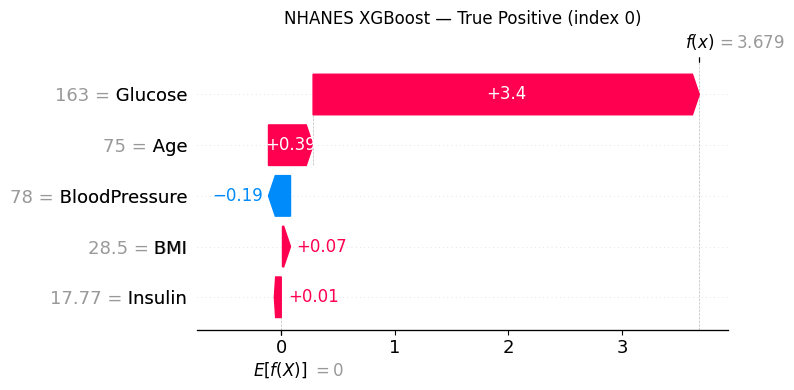

In [ ]:
#12 Waterfall plot — a confident, correct diabetic prediction
pos_idx = true_positive_idx[0]   # adjust index once you see the candidate list
print(X_test.iloc[pos_idx])
print("Predicted probability:", y_prob_xgb[pos_idx])

shap.plots.waterfall(xgb_shap_values[pos_idx], show=False)
plt.title(f"NHANES XGBoost — True Positive (index {pos_idx})")
plt.tight_layout()
plt.show()

Glucose          117.00
BloodPressure     92.00
BMI               31.90
Insulin            3.65
Age               65.00
Name: 15, dtype: float64
Predicted probability: 0.3415778


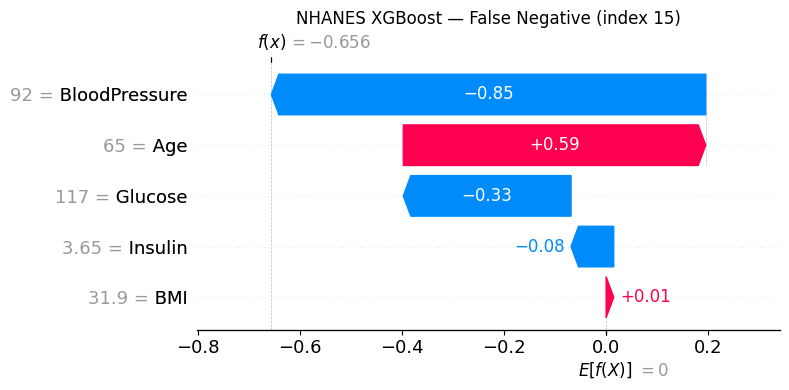

In [ ]:
#13 Waterfall plot — a misclassified case
fn_idx = false_negative_idx[0]
print(X_test.iloc[fn_idx])
print("Predicted probability:", y_prob_xgb[fn_idx])

shap.plots.waterfall(xgb_shap_values[fn_idx], show=False)
plt.title(f"NHANES XGBoost — False Negative (index {fn_idx})")
plt.tight_layout()
plt.show()